# K-Means Clustering for Smart Meter Customer Segmentation

In [6]:
import polars as pl
import glob
import numpy as np
import os
import matplotlib.pyplot as plt
from pathlib import Path
import sys
import pandas as pd

from tslearn.clustering import TimeSeriesKMeans 

from Hyperparameters_KMeans import optimize_kmeans
from IPython.core.magic import register_cell_magic
@register_cell_magic
def skip(line, cell):
    return

from importlib import reload
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score
import Silhouette_score_KMeans
from Silhouette_score_KMeans import validation_kMeans
reload(Silhouette_score_KMeans)

from Analysis import Cluster_Statistics
from Analysis.Cluster_Statistics import plot_cluster_percentiles
reload(Cluster_Statistics)

project_root = "/Users/jansigrist/Documents/SP/Customer_Segmentation_Lantern" # adjust to user environment
sys.path.insert(0, project_root)

### 1. CONFIGURATION: Dataset selection and hyperparameters

In [7]:
# Defines analysis scope: SWW/GroupE datasets, building types, clusters

dataset = "GroupE"  # Options: "SWW", "GroupE"
building_type = "house" # "flat", "house", "all"
number_of_clusters = 4  # Optimal k from silhouette analysis

print(f"Dataset: {dataset}, Building: {building_type}, k={number_of_clusters}")

Dataset: GroupE, Building: house, k=4


### 2. TIME SERIES DATA: Load hourly smart meter consumption (96 timestamps = 1 day)

In [ ]:
# Load normalized hourly averaged data into 3D numpy array

n_timestamps = 96

# Adjust 'SM_DATA_hourlyAveraged_normalized' to handle different time scales if needed. 
# Check preprocessing scripts for available options.
input_folder = Path(f"{project_root}/DATA/{dataset}/SM_DATA_hourlyAveraged_normalized")

# Alle CSV-Dateien
pattern = str(input_folder / "*.csv")
file_paths = glob.glob(pattern)

data_list = []
filename_list = []

for file_path in file_paths:
    df = pl.read_csv(file_path)

    base = os.path.basename(file_path)        # z.B. "10030.csv"
    resid, _ = os.path.splitext(base)         # "10030"

    if len(df) != n_timestamps:
        continue

    values_array = (
        df["day_avg_bruttolastgang_kwh"]
        .to_numpy()
        .reshape((1, n_timestamps, 1))
    )
    data_list.append(values_array)
    filename_list.append(resid)

if data_list:
    data_3d = np.concatenate(data_list, axis=0)
    print(f"Shape of the 3D array: {data_3d.shape}")
    train_data = data_3d
else:
    train_data = None
    print("No matching files with correct length found.")

    

Shape of the 3D array: (379, 96, 1)


### 3. SURVEY DATA: Load sociodemographic/technical features from Excel

In [9]:
# Load survey data and extract relevant columns: resident_id and Building Type

file_path = f"{project_root}/DATA/{dataset}/Survey_Data/Survey_Data_{dataset}.xlsx"

# Excel einlesen
if dataset == "SWW":
    df = pd.read_excel(
        file_path,
        skiprows=4,
        nrows=1500,
        header=None,
        dtype={10: str, 142: str}, # Columns as string
    )
    cols_to_extract = [10, 142]
elif dataset == "GroupE":
    df = pd.read_excel(
        file_path,
        skiprows=3,
        nrows=1500,
        header=None,
        dtype={0: str, 148: str}, # Columns as string
    )
    cols_to_extract = [0, 148]

# Excract relevant columns and rename
extracted_df = df.iloc[:, cols_to_extract].copy()
extracted_df.columns = ["resident_id", "building_type"]

# Check for duplicate resident_id entries
total_rows = len(extracted_df)
unique_resident_ids = extracted_df["resident_id"].nunique()

print(f"Total rows: {total_rows}")
print(f"Unique resident_id count: {unique_resident_ids}")

if total_rows > unique_resident_ids:
    print(f"There are {total_rows - unique_resident_ids} duplicate resident_id entries.")
else:
    print("No duplicate resident_id entries found.")

# Merge filename list with extracted survey data
order_df = pd.DataFrame({"resident_id": filename_list})
category_df = order_df.merge(extracted_df, on="resident_id", how="left")

# Filter valid households (exclude "No Information" + wrong building type)
rows_to_keep_indices = []
exclude_building_type = building_type

if building_type == "all":
    exclude_building_type = None
elif building_type == "house":
    exclude_building_type = "Flat"
elif building_type == "flat":
    exclude_building_type = "House"

if building_type != "all":
    for i, row in category_df.iterrows():
        # Check if 'No Information' NOT in any value of that row
        if "No Information" not in row.values:
            # Check if 'Flat' NOT in any value of that row
            if exclude_building_type not in row.values:
                rows_to_keep_indices.append(i)
else:
    for i, row in category_df.iterrows():
        rows_to_keep_indices.append(i)

train_data = train_data[rows_to_keep_indices, :, :]

print(f"Number of samples after cleaning: {train_data.shape[0]}")

filename_list = [filename_list[i] for i in rows_to_keep_indices]

Total rows: 379
Unique resident_id count: 379
No duplicate resident_id entries found.
Number of samples after cleaning: 212


### 4. VALIDATION: Find optimal cluster number and hyperparameters from Silhouete score analysis

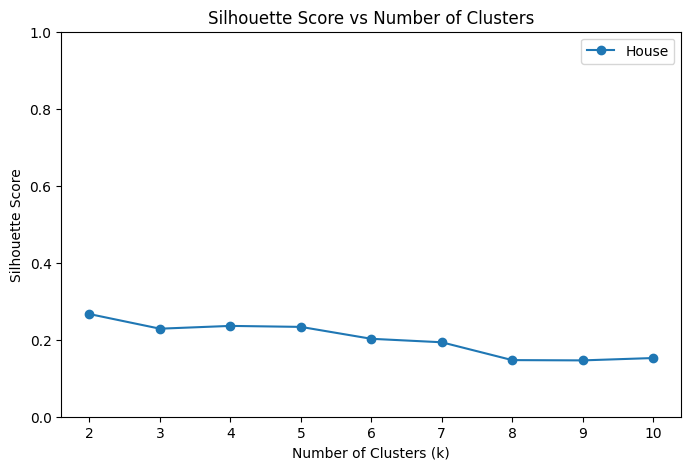


Best combination of hyperparameters:
n_clusters                 10
init                k-means++
n_init                      5
max_iter                  500
silhouette_score     0.188898
db_score             1.396807
Name: 199, dtype: object
0.23589628776233354
1.4943793832519285


In [10]:
# Validate KMeans clustering

validation_kMeans(project_root, train_data, train_data, dataset, building_type)

kmeans = TimeSeriesKMeans(n_clusters=number_of_clusters,max_iter=500, verbose=False, random_state=42,n_init=2, n_jobs=-1)
labels_clusters = kmeans.fit_predict(train_data.reshape((train_data.shape[0], train_data.shape[1])))
            
sh = silhouette_score(train_data.reshape((train_data.shape[0], train_data.shape[1])), labels_clusters)
db = davies_bouldin_score(train_data.reshape((train_data.shape[0], train_data.shape[1])), labels_clusters)

optimize_kmeans(train_data)

print(sh)
print(db)


### 5. K-MEANS CLUSTERING: Optimal k from silhouette analysis

In [11]:
# KMeans clustering with optimized parameters

max_iterations =200
n_init = 3

kmeans = TimeSeriesKMeans(n_clusters=number_of_clusters, max_iter=max_iterations, verbose=False, random_state=42,n_init=n_init, n_jobs=-1)
clusters_train = kmeans.fit_predict(train_data)

### 6. RESULTS EXPORT: Cluster assignments with household IDs

In [12]:
# saves the found clusters in a csv file with the corresponding household IDs

# Convert filename_list items to strings
resident_ids = [str(h) for h in filename_list]

# Creates Polars DataFrame with house IDs and clusters
result_df = pl.DataFrame({
    "resident_id": resident_ids,
    "cluster": clusters_train + 1
}).sort("cluster")

result_df.write_csv(f"{project_root}/Results/{dataset}/DATA/Cluster/hourly_avg_clustering_kMeans_{building_type}_{'technical'}.csv")

### 7. ANALYSIS: Visualization of consumption profiles, statistical analysis, PAR calculation, distribution of features

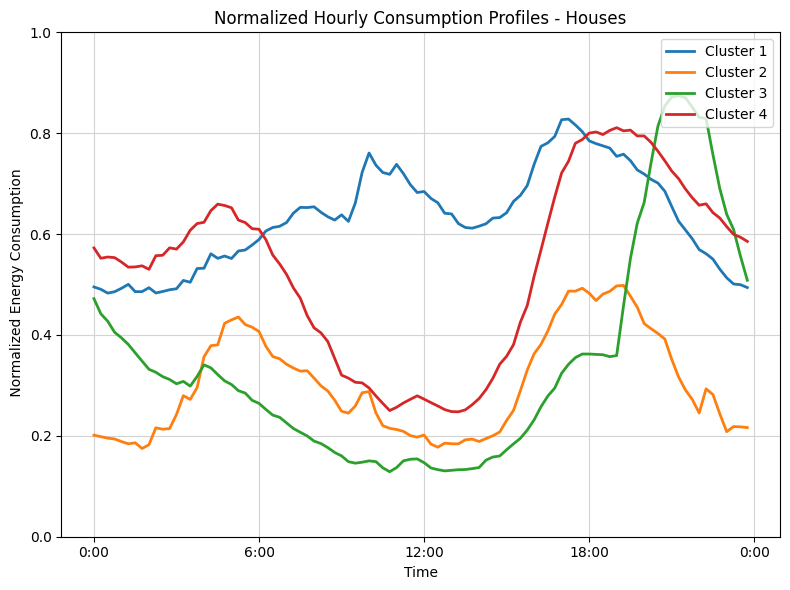

In [13]:
# Plot the clustered mean time series

labels = ['0:00','6:00','12:00','18:00','0:00']

colors= ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728','#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']

n_clusters = len(np.unique(clusters_train))

plt.figure(figsize=(8,6))
for cluster_idx in range(n_clusters):
    # Get all time series in this cluster
    cluster_data = train_data[clusters_train == cluster_idx]
    cluster_indices = np.where(clusters_train == cluster_idx)[0]    

    # Calculate the mean time series for the cluster
    mean_time_series = np.mean(cluster_data, axis=0)
    
    # Plot the mean time series
    cluster_no = cluster_idx+1
    plt.plot(range(1,97), mean_time_series.ravel(), 
            label= f'Cluster {cluster_no}',
            linewidth =2, color=colors[cluster_idx] )
plt.title(f'Normalized Hourly Consumption Profiles - {building_type.capitalize()}s')
plt.xlabel("Time")
plt.ylabel(" Normalized Energy Consumption")
plt.ylim(0,1)
plt.xticks(range(1,120,24),labels=labels)
plt.tight_layout()
plt.grid(True, color = 'lightgray')
plt.legend(
loc='upper right',
bbox_to_anchor=(1, 1),
ncol=1,
fontsize='medium'
)
plt.savefig(
f"{project_root}/Results/{dataset}/Plots/Cluster/HourlyAveraged_KMeans_{building_type}.png",
bbox_inches='tight'
)
plt.show()

In [14]:
# Cluster summary statistics

alle_mittelwerte_df = pl.read_csv(f"{project_root}/DATA/{dataset}/dataset_summary_stats.csv")

alle_mittelwerte_df = alle_mittelwerte_df.with_columns(
    pl.col("file_id")
      .cast(pl.Utf8)
      .str.strip_chars()
      .str.to_lowercase()
      .alias("resident_id")
)

result_df = result_df.join(
    alle_mittelwerte_df.select([
        "resident_id",
        "bruttolastgang_kwh_sum",
        "average_daily_consumption"
    ]),
    on="resident_id",
    how="left"
)
result_df = result_df.select([
    "resident_id",
    "cluster",
    "bruttolastgang_kwh_sum",
    "average_daily_consumption"  
])

cluster_summary = result_df.group_by("cluster").agg([
    pl.count("resident_id").alias("num_households"),
    pl.mean("bruttolastgang_kwh_sum").alias("avg_yearly_consumption [kWh]").round(2),
    pl.mean("average_daily_consumption").alias("avg_daily_consumption [kWh]").round(2)
]).sort("cluster")

# Compute overall averages
overall_yearly_avg = round(result_df["bruttolastgang_kwh_sum"].mean(),2)
overall_seasonal_avg = round(result_df['average_daily_consumption'].mean(),2)

cluster_summary = cluster_summary.with_columns([
    pl.col("cluster").cast(pl.Utf8)
])
summary_row = pl.DataFrame({
    "cluster": ["Combined"], 
    "num_households": [result_df["resident_id"].n_unique()],
    "avg_yearly_consumption [kWh]": [overall_yearly_avg],
    "avg_daily_consumption [kWh]": [overall_seasonal_avg]
})

# Ensure dtypes match for concatenation
summary_row = summary_row.with_columns([
    pl.col("cluster").cast(cluster_summary["cluster"].dtype),
    pl.col("num_households").cast(cluster_summary["num_households"].dtype)
])

# Concatenate now that dtypes match
final_summary = pl.concat([cluster_summary, summary_row])

print(final_summary)

shape: (5, 4)
┌──────────┬────────────────┬──────────────────────────────┬─────────────────────────────┐
│ cluster  ┆ num_households ┆ avg_yearly_consumption [kWh] ┆ avg_daily_consumption [kWh] │
│ ---      ┆ ---            ┆ ---                          ┆ ---                         │
│ str      ┆ u32            ┆ f64                          ┆ f64                         │
╞══════════╪════════════════╪══════════════════════════════╪═════════════════════════════╡
│ 1        ┆ 34             ┆ 3305.09                      ┆ 13.68                       │
│ 2        ┆ 38             ┆ 2767.06                      ┆ 11.64                       │
│ 3        ┆ 73             ┆ 4378.85                      ┆ 18.43                       │
│ 4        ┆ 67             ┆ 3596.58                      ┆ 15.0                        │
│ Combined ┆ 212            ┆ 3670.51                      ┆ 15.37                       │
└──────────┴────────────────┴──────────────────────────────┴────────────────

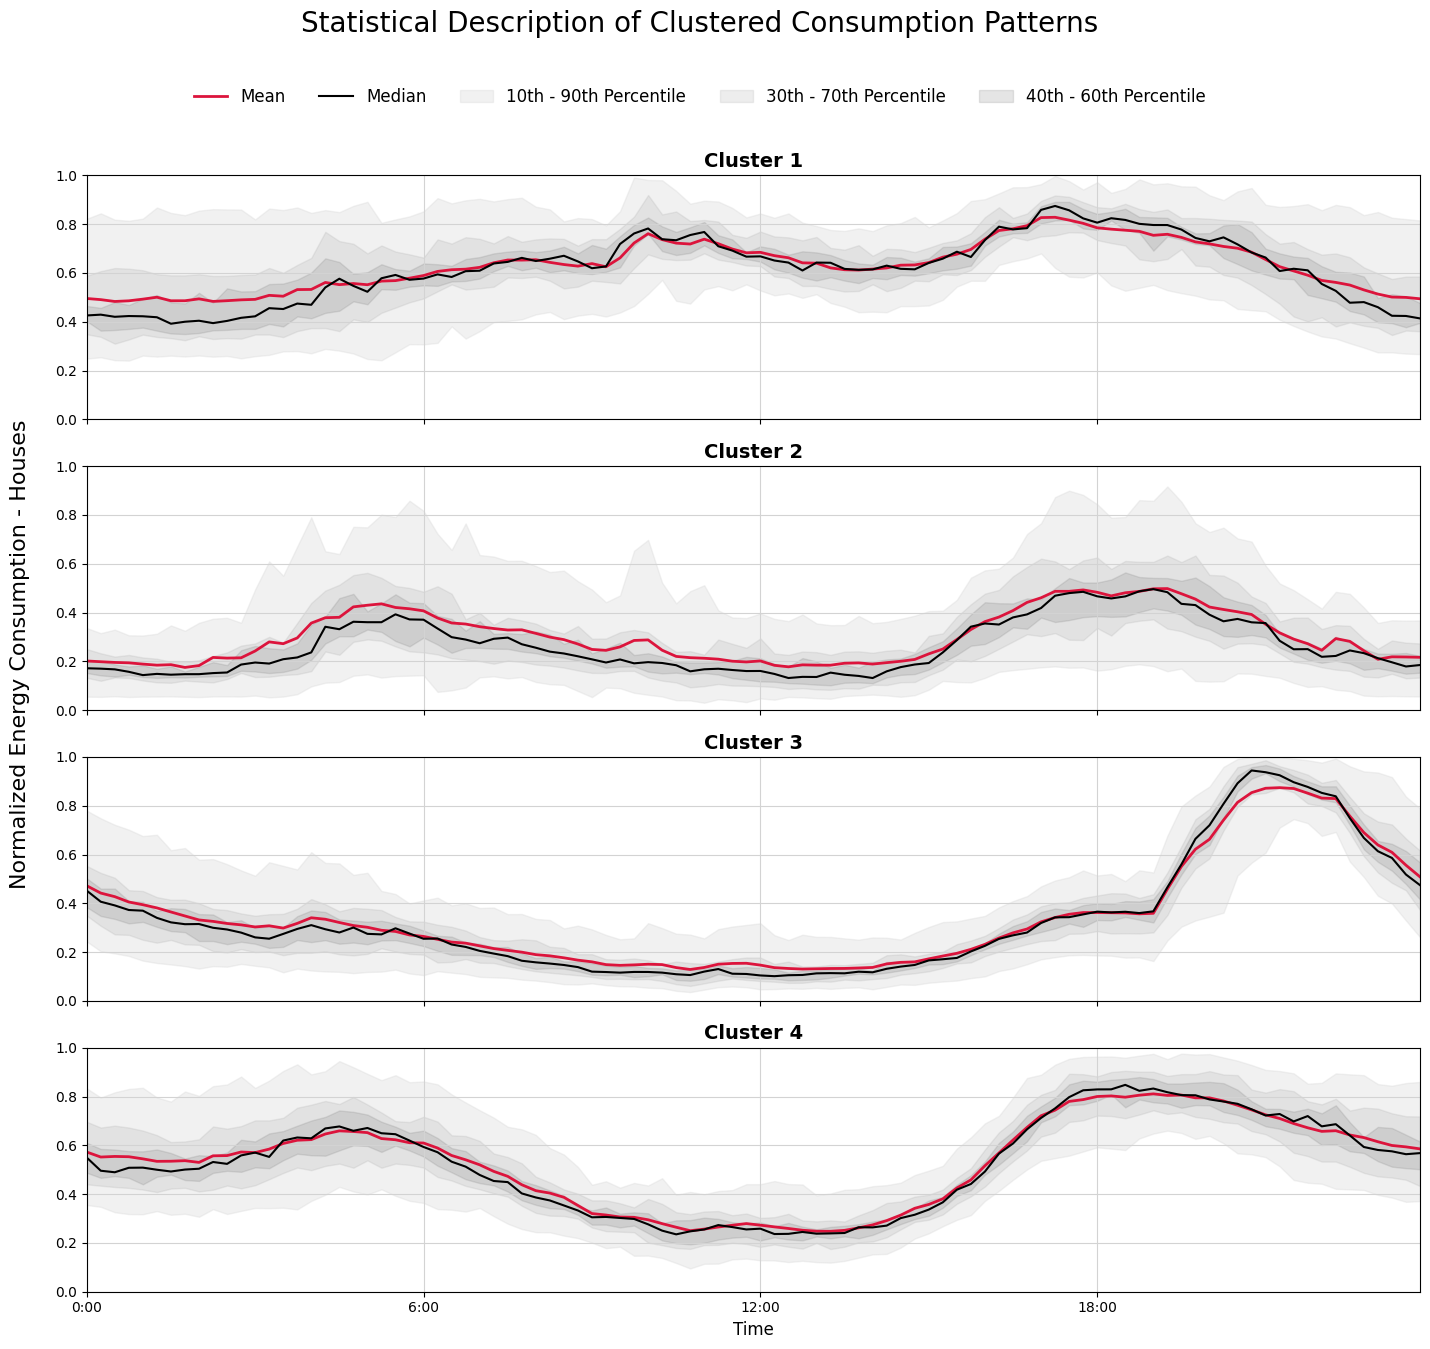

In [15]:
# Plot cluster percentiles

clusters_train = clusters_train + 1  # Shift cluster labels to start from 1

for i in range(number_of_clusters):

    i = i+1
    # Select samples for the current cluster
    cluster_data = train_data[clusters_train == i]
    
    if cluster_data.shape[0] == 0:
        print(f"Warning: cluster {i} is empty, skipping.")
        continue  # Skip this cluster

plot_cluster_percentiles(project_root, train_data,clusters_train,number_of_clusters, building_type, dataset, 'kMeans', 'all_features')

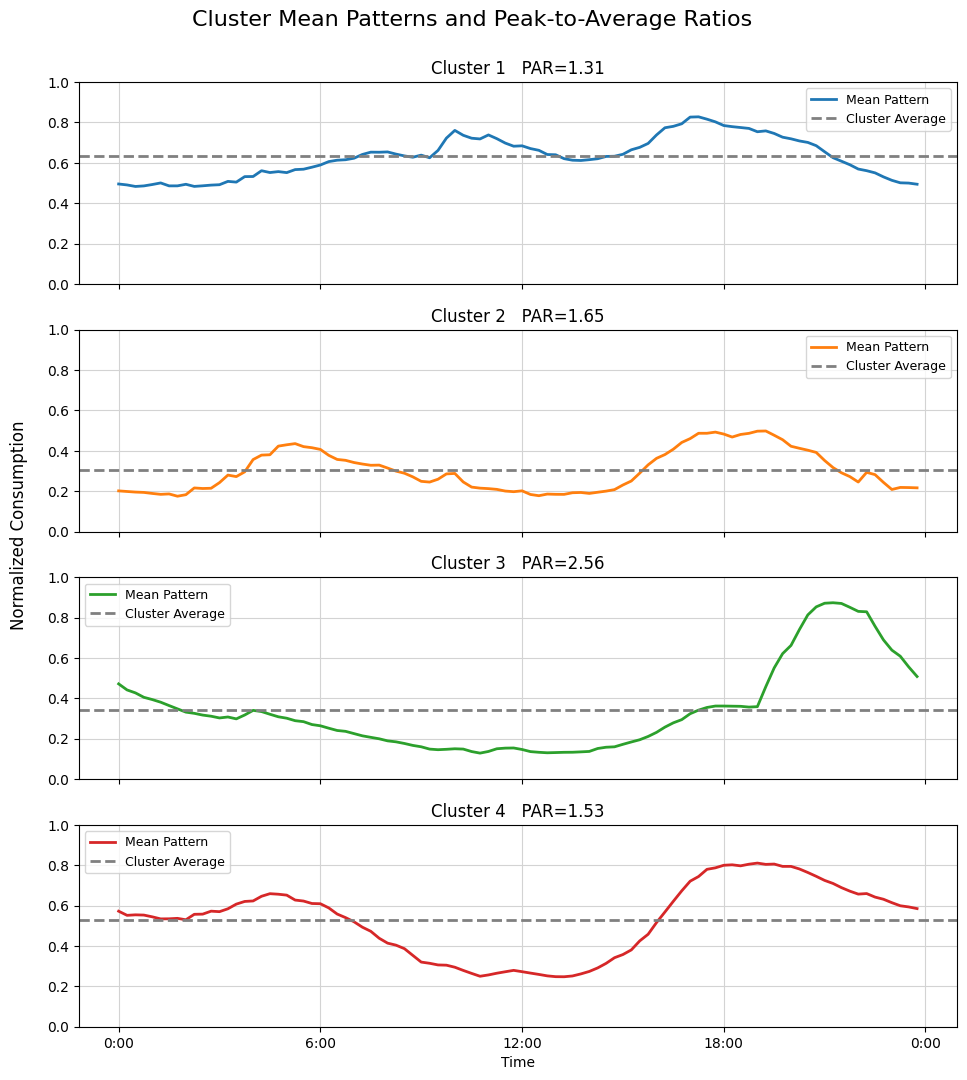

In [16]:
# Plot Mean Patterns and Peak-to-Average Ratios (PAR)

labels = ['0:00', '6:00', '12:00', '18:00', '0:00']
colors= ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728','#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']


clusters = clusters_train  # Cluster labels starting from 1
time_series_numeric = train_data.reshape((train_data.shape[0], train_data.shape[1]))

n_clusters_to_plot = np.unique(clusters)
n_clusters = len(n_clusters_to_plot)

fig, axes = plt.subplots(n_clusters, 1, figsize=(10, 2.8 * n_clusters), sharex=True)

if n_clusters == 1:
    axes = [axes]

for idx, cl in enumerate(sorted(n_clusters_to_plot)):  # Cluster 1 oben
    cluster_idx = np.where(clusters == cl)[0]
    mean_time_series = time_series_numeric[cluster_idx].mean(axis=0)
    PAR_average = np.mean(mean_time_series)
    PAR_max = np.max(mean_time_series)

    ax = axes[idx]
    ax.plot(range(1,97), mean_time_series.ravel()[:96],
            label='Mean Pattern', linewidth=2, color=colors[cl-1])
    ax.axhline(PAR_average, color='grey', linestyle='--', linewidth=2, label='Cluster Average')
    ax.set_title(f"Cluster {cl}   PAR={PAR_max/PAR_average:.2f}",
                 loc='center', fontsize=12, color='black')
    ax.set_ylim(0, 1)
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.grid(color='lightgray', zorder=0)
    ax.legend(fontsize=9)
    if idx == n_clusters-1:
        ax.set_xlabel("Time")
        ax.set_xticks(range(1,120,24))
        ax.set_xticklabels(labels)
    else:
        ax.set_xticks([])  # Keine X-Ticks für die oberen Subplots
    # ACHTUNG: Kein ax.set_ylabel() hier!

fig.suptitle("Cluster Mean Patterns and Peak-to-Average Ratios", fontsize=16,  y=0.96)
fig.text(0.038, 0.5, "Normalized Consumption", va='center', rotation='vertical', fontsize=12)

plt.tight_layout(rect=[0.06, 0, 1, 0.96])
plt.savefig(
    f"{project_root}/Results/{dataset}/Plots/Cluster/PAR_KMeans_{building_type}.png",
    bbox_inches='tight'
)
plt.show()